# ДЗ 2. Прогнозирование продаж: построение и оценка моделей
Товар `85099B JUMBO BAG RED RETROSPOT`, ряды из ДЗ 1 (день / неделя / месяц, штуки в рабочий день).
Логика — в `forecast.py` (модели, бэктест, метрики) и `../HW1/retail_ts.py` (подготовка ряда).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import forecast as fc

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 100

## 1. Данные
### 1.1 Ряды из ДЗ 1

In [2]:
S = fc.load_series()
fc.check_index(S)

,n,начало,конец,по возрастанию,дубликаты,"шаги, дней (число)",пропусков
день,313,2010-12-01,2011-11-30,True,0,"{1: 260, 2: 52}",16
неделя,52,2010-12-05,2011-11-27,True,0,{7: 51},1
месяц,12,2010-12-01,2011-11-01,True,0,"{28: 1, 30: 3, 31: 7}",0


- Индекс по возрастанию, без дубликатов.
- **День:** шаг 1 день, а между пятницей и воскресеньем — 2 дня: суббот в календаре магазина нет (ДЗ 1). Пропуски — 16 праздников.
- **Неделя:** шаг 7 дней, пропущена рождественская неделя. Неделя 28–30.11, обрезанная концом периода, отброшена.
- **Месяц:** 12 точек без пропусков.

При обучении пропуски заполняются линейной интерполяцией **только внутри обучающей части**. Метрики считаются только по реально наблюдённым значениям.

### 1.2 Разбиение на обучение и тест: скользящее начало прогноза
Одно разбиение «train / test» даёт для горизонта 1 всего **одну** тестовую точку — оценка была бы случайной. Поэтому используем **бэктест со скользящим началом** (rolling origin, expanding window):
1. Выбираем момент — начало прогноза. Модель учится только на данных **до** него.
2. Прогнозируем на max(h) шагов вперёд и сравниваем с фактом.
3. Сдвигаем начало вперёд, переобучаем, повторяем.

Будущее в обучение не попадает: на каждом начале модель видит только прошлое. Последнее начало оставляет ровно max(h) шагов до конца ряда, поэтому все горизонты оцениваются на одних и тех же началах.

In [3]:
pd.DataFrame({fr: {"сезонный период m": c["m"], "горизонты": c["horizons"], "начал": c["n_origins"],
                   "шаг между началами": c["step"],
                   "обучение на 1-м начале": fc.make_origins(len(S[fr]), c)[0],
                   "первое начало": S[fr].index[fc.make_origins(len(S[fr]), c)[0]].date(),
                   "последнее начало": S[fr].index[fc.make_origins(len(S[fr]), c)[-1]].date()}
              for fr, c in fc.CONFIG.items()}).T

,сезонный период m,горизонты,начал,шаг между началами,обучение на 1-м начале,первое начало,последнее начало
день,6,"[1, 7, 31, 61]",8,6,210,2011-08-03,2011-09-21
неделя,1,"[1, 4, 8]",8,1,37,2011-08-21,2011-10-09
месяц,1,"[1, 2]",2,1,9,2011-09-01,2011-10-01


- **День:** 8 начал через неделю (6 рабочих дней), август–сентябрь; каждое начало даёт прогноз на 61 день.
- **Неделя:** 8 начал подряд, прогноз на 8 недель.
- **Месяц:** 12 точек хватает только на 2 начала (обучение 9 и 10 месяцев). Оценки по месяцам — по 2–4 точкам, это очень шумно, выводы по ним осторожные.

## 2. Модели
| Модель | Идея | Настройка |
|---|---|---|
| **Наивный** (бейзлайн) | завтра = сегодня; для дня — сезонный: как в тот же день прошлой недели | — |
| **ETS** (Holt–Winters) | экспоненциальное сглаживание уровня, тренда и сезонности: свежие наблюдения весят больше | затухающий тренд; недельная сезонность (6) — только у дня |
| **ARIMA** | линейная модель от прошлых значений (AR) и прошлых ошибок (MA) | порядок по AIC на первом обучении; d = 0 и линейный тренд — ряд тренд-стационарен (ДЗ 1); у дня — SARIMA с периодом 6 |
| **LightGBM** (бустинг) | градиентный бустинг деревьев на признаках: лаги, скользящее среднее, день недели | рекурсивный прогноз: каждый прогноз становится лагом для следующего шага |

Все модели, кроме наивной, учатся на **Box–Cox** (ДЗ 1: стабилизирует дисперсию). λ оценивается только на обучающей части, прогноз переводится обратно в штуки.
Все модели вызываются через одну сигнатуру `f(y_train, h) → прогноз длины h` — это и обеспечивает одинаковые условия сравнения.

## 3. Метрики
| Метрика | Формула | Зачем |
|---|---|---|
| **MAE** | mean \|y − ŷ\| | ошибка в штуках, легко интерпретировать |
| **RMSE** | √mean (y − ŷ)² | сильнее штрафует крупные промахи (оптовые заказы) |
| **WAPE** | Σ\|y − ŷ\| / Σy | доля ошибки от объёма продаж; не зависит от масштаба, работает при нулевых продажах |
| **MASE** | MAE / MAE наивного прогноза на обучении | < 1 — лучше наивного в среднем; не зависит от масштаба |

**MAPE не используем:** в дневном ряде есть дни с 0 и 1–2 шт., деление на них взрывает метрику.
Ряды разных частот в разных масштабах, поэтому **сравниваем частоты по WAPE и MASE**, а MAE/RMSE — только внутри одной частоты.
Метрика горизонта h считается по всем шагам 1..h всех начал: «насколько точен прогноз на ближайшие h шагов».

## 4. Эксперименты

In [4]:
results, forecasts, orders = [], {}, {}
for fr, cfg in fc.CONFIG.items():
    f, mt, order, origins = fc.run_experiment(S[fr], cfg)
    forecasts[fr], orders[fr] = f, order
    results.append(mt.assign(частота=fr))
results = pd.concat(results, ignore_index=True)[["частота", "h", "model", "MAE", "RMSE", "WAPE", "MASE", "начал", "точек"]]
print("Порядок ARIMA (p,d,q)(P,D,Q,m), подобран по AIC:", orders)
results.to_csv("results_metrics.csv", index=False)
pd.concat([f.assign(частота=fr) for fr, f in forecasts.items()]).to_csv("results_forecasts.csv", index=False)
results.round(3)

Порядок ARIMA (p,d,q)(P,D,Q,m), подобран по AIC: {'день': ((1, 0, 1), (1, 0, 1, 6)), 'неделя': ((0, 0, 0), (0, 0, 0, 0)), 'месяц': ((0, 0, 0), (0, 0, 0, 0))}


,частота,h,model,MAE,RMSE,WAPE,MASE,начал,точек
0,день,1,ARIMA,267.144,378.920,0.764,1.987,8,8
1,день,1,ETS,276.062,392.172,0.789,2.051,8,8
2,день,1,LightGBM,296.505,423.037,0.848,2.202,8,8
3,день,1,Наивный,422.875,505.394,1.209,3.116,8,8
4,день,7,ARIMA,146.909,237.254,0.683,1.093,8,55
5,день,7,ETS,149.000,246.513,0.693,1.109,8,55
6,день,7,LightGBM,159.279,256.095,0.741,1.186,8,55
7,день,7,Наивный,212.082,294.574,0.987,1.569,8,55
8,день,31,ARIMA,133.891,233.873,0.688,0.986,8,244
9,день,31,ETS,134.536,243.470,0.691,0.991,8,244


Полная таблица: модель × частота × горизонт × метрики. Сохранена в `results_metrics.csv`, все прогнозы — в `results_forecasts.csv`.
- ARIMA для дня — SARIMA(1,0,1)(1,0,1,6): короткая память плюс недельная сезонность. Для недели и месяца AIC выбрал (0,0,0) с трендом, то есть «линейный тренд + шум»: значимой автокорреляции нет (совпадает с ACF из ДЗ 1).

### 4.1 Сводная таблица

In [5]:
summary = results.pivot_table(index=["частота", "h"], columns="model", values=["WAPE", "MASE"], sort=False).round(2)
summary

WAPE                         MASE                       
model      ARIMA   ETS LightGBM Наивный ARIMA   ETS LightGBM Наивный
частота h                                                           
день    1   0.76  0.79     0.85    1.21  1.99  2.05     2.20    3.12
        7   0.68  0.69     0.74    0.99  1.09  1.11     1.19    1.57
        31  0.69  0.69     0.71    0.97  0.99  0.99     1.02    1.39
        61  0.70  0.69     0.71    0.95  1.04  1.03     1.06    1.40
неделя  1   0.41  0.40     0.39    0.45  1.38  1.34     1.31    1.52
        4   0.42  0.41     0.42    0.53  1.28  1.26     1.28    1.64
        8   0.41  0.41     0.43    0.49  1.32  1.32     1.38    1.58
месяц   1   0.07  0.03     0.29    0.17  0.32  0.15     1.30    0.78
        2   0.10  0.05     0.33    0.18  0.51  0.27     1.60    0.89

In [6]:
best = results.loc[results.groupby(["частота", "h"], sort=False).MASE.idxmin(), ["частота", "h", "model", "MASE", "WAPE"]]
best.round(2)

,частота,h,model,MASE,WAPE
0,день,1,ARIMA,1.99,0.76
4,день,7,ARIMA,1.09,0.68
8,день,31,ARIMA,0.99,0.69
13,день,61,ETS,1.03,0.69
18,неделя,1,LightGBM,1.31,0.39
21,неделя,4,ETS,1.26,0.41
25,неделя,8,ETS,1.32,0.41
29,месяц,1,ETS,0.15,0.03
33,месяц,2,ETS,0.27,0.05


## 5. Визуализация
### 5.1 Факт и прогнозы (последнее начало)

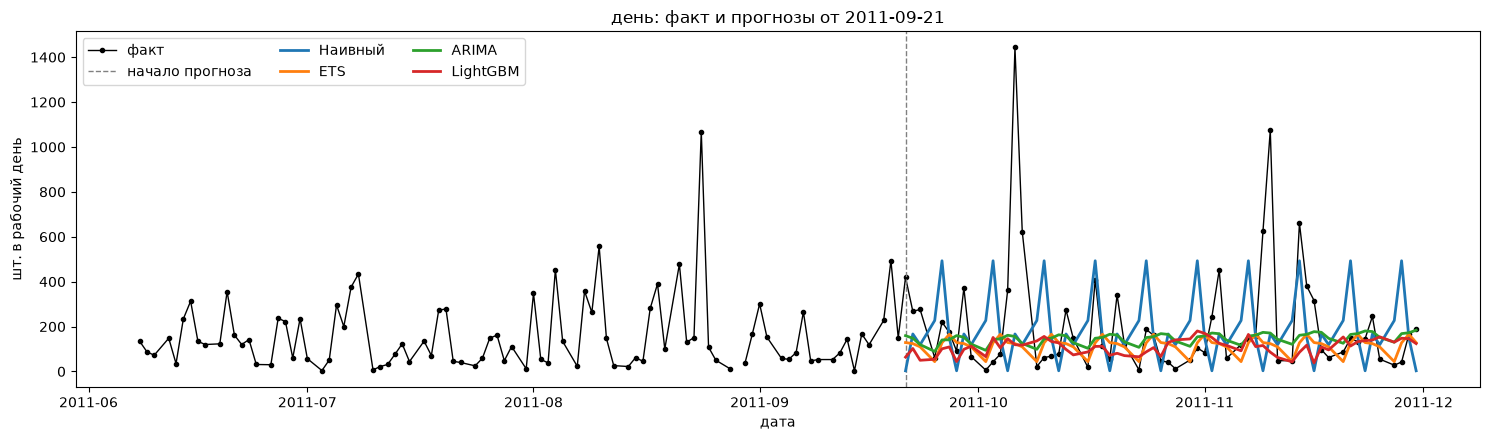

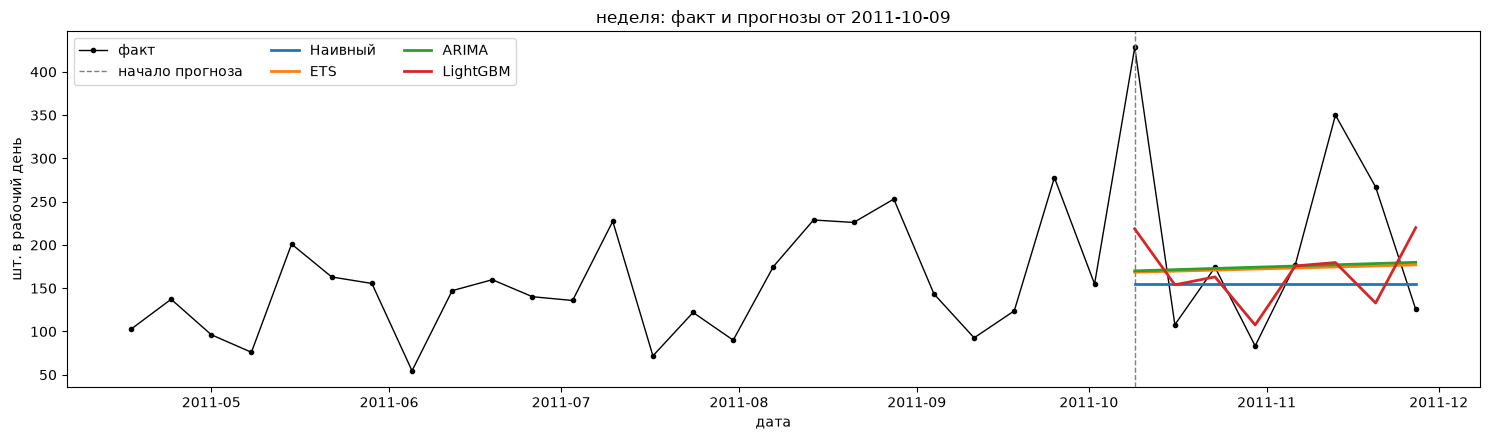

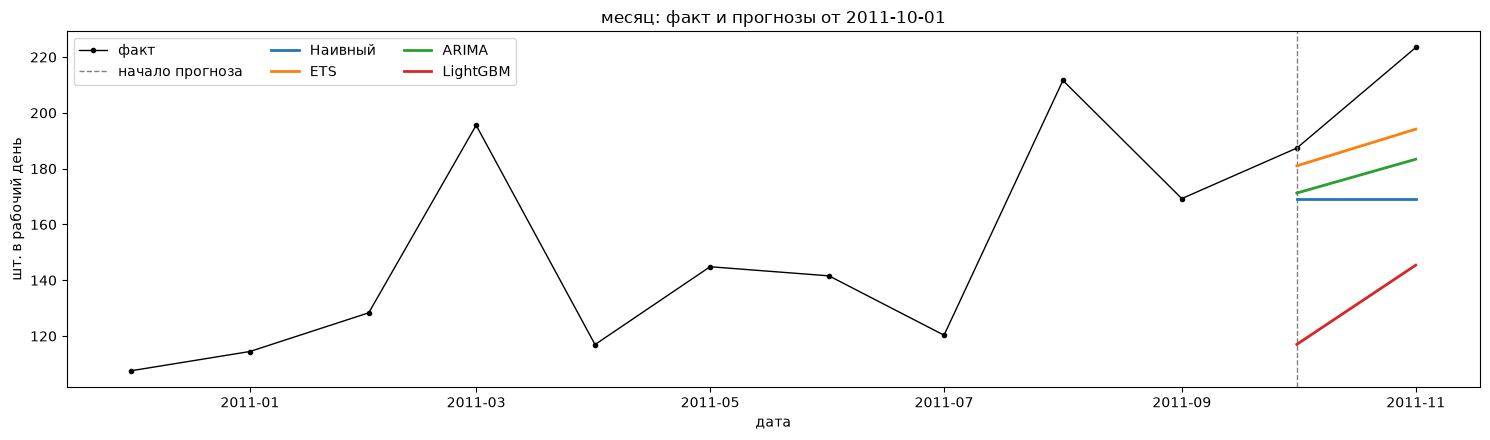

In [7]:
for fr, hist in [("день", 90), ("неделя", 25), ("месяц", 12)]:
    f = forecasts[fr]
    fc.plot_forecasts(S[fr], f, f.origin.max(), f"{fr}: факт и прогнозы от {f.origin.max().date()}", history=hist);

- **День:** ни одна модель не пытается угадать отдельные пики — это оптовые заказы, они непредсказуемы по истории ряда. Модели прогнозируют **средний уровень и недельный профиль** (провал в воскресенье). Сезонный наивный повторяет прошлую неделю целиком, вместе с её случайными пиками, — отсюда его большая ошибка.
- **Неделя:** ETS и ARIMA дают почти ровную линию на уровне последних недель, LightGBM — похожий уровень с небольшими колебаниями.
- **Месяц:** ETS и ARIMA продлевают рост, LightGBM не умеет экстраполировать и остаётся в диапазоне обучающих значений.

### 5.2 Качество по горизонтам

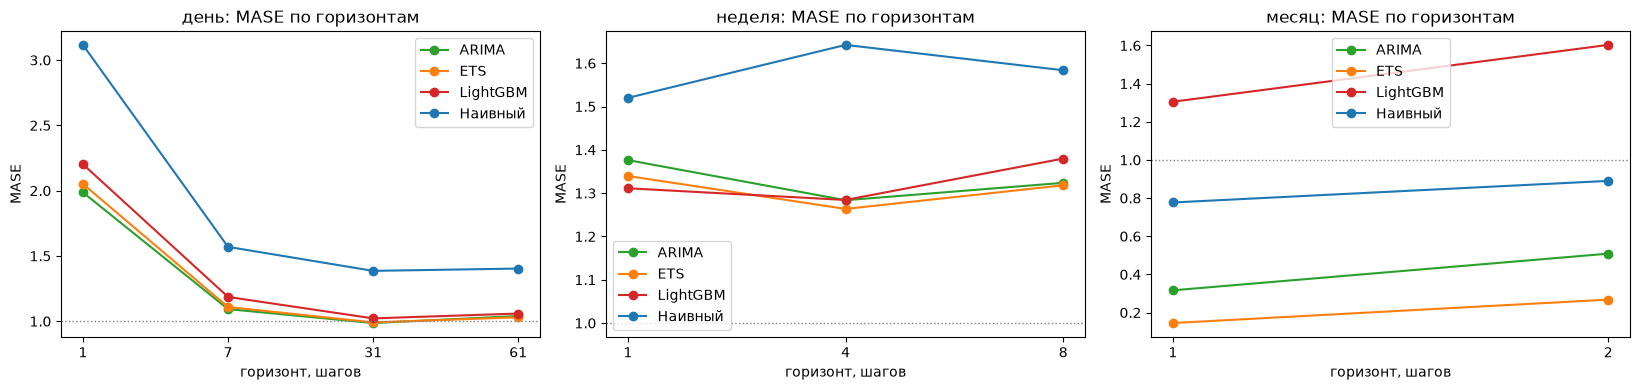

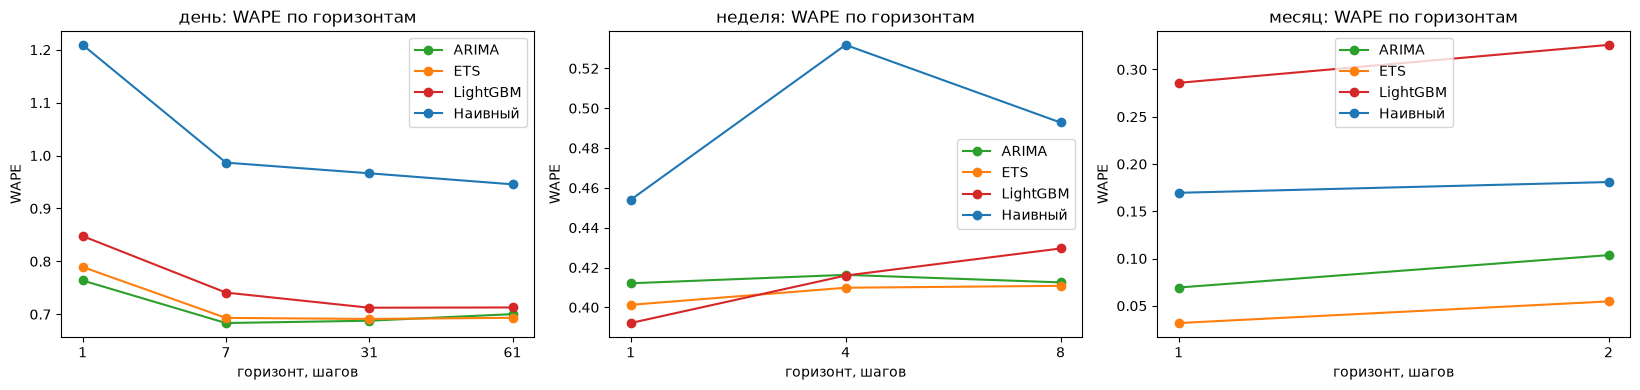

In [8]:
fc.plot_metric_by_horizon(results, "MASE");
fc.plot_metric_by_horizon(results, "WAPE");

Пунктир на MASE = 1 — средняя ошибка наивного прогноза **на обучении**. На тесте (осень) продажи выше и шумнее, поэтому MASE > 1 бывает даже у моделей, которые лучше наивного **на тех же тестовых точках**. Для сравнения моделей важно их взаимное расположение.

## 6. Выводы
**Лучшие модели**
- **День:** ARIMA (SARIMA) и ETS — практически вровень (WAPE ≈ 0.69 на горизонтах 7–61), LightGBM чуть хуже (≈ 0.71–0.74), сезонный наивный хуже всех (≈ 0.95–1.2).
- **Неделя:** ETS, ARIMA и LightGBM близки (WAPE ≈ 0.39–0.43), все лучше наивного (0.45–0.53). На 1 шаг чуть лучше LightGBM, на 4–8 — ETS; разница в пределах шума.
- **Месяц:** лучший — ETS (WAPE 3–5 %), затем ARIMA; LightGBM хуже наивного. Но оценка — по 2–4 точкам.

**Горизонт**
- **День:** ошибка за 1 шаг выше, чем за 7–61. Это не «прогноз на месяц точнее, чем на завтра»: один день — это 8 точек, и каждая может быть оптовым заказом; на длинном окне ошибки отдельных дней усредняются. Начиная с 7 дней качество почти не меняется — модели прогнозируют уровень и недельный профиль, а они меняются медленно.
- **Неделя:** качество почти не зависит от горизонта 1–8: сильной краткосрочной памяти в ряде нет (ARIMA выбрала (0,0,0)), прогноз на любой горизонт — это уровень плюс тренд.
- **Месяц:** ошибка растёт с горизонтом у всех моделей (у ETS WAPE 3 % → 5 %): чем дальше прогноз, тем больше накопленная неопределённость тренда.

**Ограничения и причины ошибок**
- Основная ошибка дневного прогноза — **оптовые заказы**: всплески на 1000+ шт. не предсказуемы по истории продаж. WAPE ≈ 0.7 — это в основном они.
- **LightGBM** не экстраполирует тренд (деревья предсказывают в диапазоне обучения) и на 7–9 месяцах обучения бесполезен. Первая версия с признаками «отклонение от уровня» на рекурсивном прогнозе накапливала ошибку и уходила в рост — от неё пришлось отказаться.
- **Месячный ряд** слишком короткий: 9–10 точек на обучение, 2 начала на тест. Выводы по нему ненадёжны.
- Прогноз Box–Cox после обратного преобразования ближе к медиане, чем к среднему, — при скошенном распределении продаж он систематически немного занижен.